# Experiment 01A : Vascular Drug Exchange Sensitivity

**Drug Modeled** : Gefitinib

**Research Question** : How does vascular exchange introduce gefitinib into tumor tissue, and how does the resulting concentration field evolve over time?

**Independent Parameter** : Vascular exchange coefficient, $P_v$

**Primary Outputs** : 

* Tissue concentration field $C(x, y, t)$
* Mean tissue concentration
* Concentration versus distance from vessel
* Drug penentration
* Total drug accumulation in tissue

## Preliminary Definitions

* **$x = 0$** : Robin condition, Blood vessel exchanges drug with tissue
* **$x = L_x$** : Zero flux condition, Distal symmetry boundary
* **$y = 0, L_y$** : Periodic condition, Repeating lateral tissue strip

The vascular boundary is : 

$$J_{in} = P_v * (C_v - C_{wall})$$

where:
* $P_v$ : vascular exchange coefficient, cm/s
* $C_v$ : effective vascular drug concentration (set to 1 for simplicity)
* $C_{wall}$ : tissue-side concentration at the vessel interface
* $J_{in}$ : drug flux entering the tissue

## I. Baseline Vascular Exchange

Constant vascular source, conservative flux implementation, mass balance verification.

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Load shared model parameters
with open("Parameters/model_params.json", "r") as f:
    params = json.load(f)

# Spatial parameters
Lx = params["Lx"]
Ly = params["Ly"]
Nx = params["Nx"]
Ny = params["Ny"]

# Grid spacing
dx = Lx / Nx
dy = Ly / Ny

# Cell-center coordinates
x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy

# Coordinate matrices
X, Y = np.meshgrid(x, y, indexing="ij")

In [23]:
# ==========================================
# EXPERIMENT 01A — VASCULAR EXCHANGE
# ==========================================

# Baseline diffusivity
D = params["D0"]  # cm^2/s

# Vascular exchange coefficient
Pv = params["Pv"]  # cm/s

# Normalized vascular concentration
Cv = 1.0

# Drug initially absent from tissue
C = np.zeros((Nx, Ny))

# ==========================================
# EXPERIMENT-SPECIFIC SIMULATION SETTINGS
# ==========================================

dt = 0.01  # s
T = 60.0   # s
Nt = int(T / dt)

save_times = [0, 1, 5, 15, 30, 60]

In [5]:
def diffusion_step_vascular(C, D, Pv, Cv, dx, dy, dt):

    Nx, Ny = C.shape

    # ---------------------------------------
    # X-direction fluxes
    # ---------------------------------------

    Fx = np.zeros((Nx + 1, Ny))

    # Internal fluxes between tissue cells
    Fx[1:-1, :] = -D * (
        C[1:, :] - C[:-1, :]
    ) / dx

    # Vascular boundary at x = 0
    # Effective permeability accounts for half-cell diffusion
    P_eff = 1 / (
        1 / Pv + dx / (2 * D)
    )

    Fx[0, :] = P_eff * (Cv - C[0, :])

    # Distal boundary: zero flux
    Fx[-1, :] = 0


    # ---------------------------------------
    # Y-direction fluxes (periodic)
    # ---------------------------------------

    Fy = np.zeros((Nx, Ny + 1))

    # Internal fluxes
    Fy[:, 1:-1] = -D * (
        C[:, 1:] - C[:, :-1]
    ) / dy

    # Periodic connection between last and first cells
    periodic_flux = -D * (
        C[:, 0] - C[:, -1]
    ) / dy

    Fy[:, 0] = periodic_flux
    Fy[:, -1] = periodic_flux


    # ---------------------------------------
    # Flux divergence
    # ---------------------------------------

    divergence_x = (
        Fx[1:, :] - Fx[:-1, :]
    ) / dx

    divergence_y = (
        Fy[:, 1:] - Fy[:, :-1]
    ) / dy

    divergence = divergence_x + divergence_y


    # ---------------------------------------
    # Update concentration
    # ---------------------------------------

    C_new = C - dt * divergence

    return C_new

In [6]:
# Reset tissue concentration
C = np.zeros((Nx, Ny))

# Store concentration snapshots
saved_C = {0: C.copy()}

# Run simulation
for step in range(1, Nt + 1):

    C = diffusion_step_vascular(
        C, D, Pv, Cv, dx, dy, dt
    )

    t = step * dt

    if step in [int(target / dt) for target in save_times]:
        saved_C[int(round(t))] = C.copy()

print("Experiment 01A simulation complete.")

Experiment 01A simulation complete.


/var/folders/sj/6mw6cz_x1dg1nlhv9xgk5rgh0000gn/T/ipykernel_99515/564534934.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


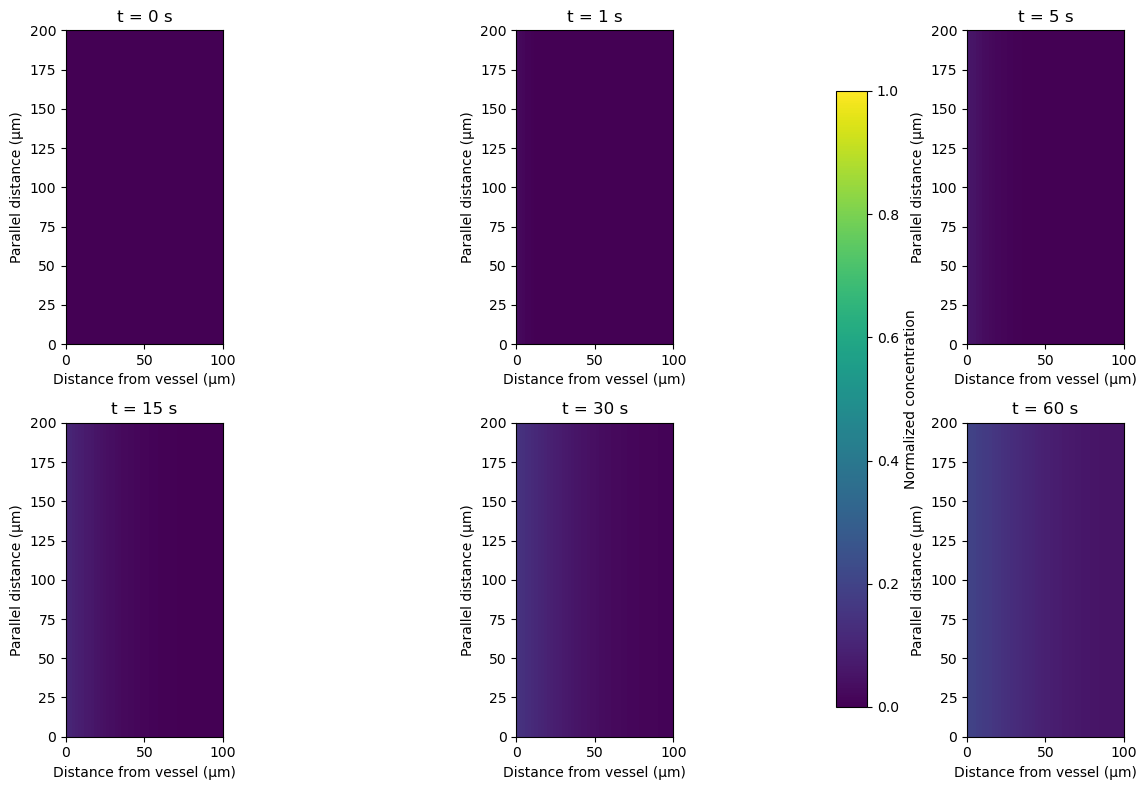

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, t in zip(axes.flat, save_times):

    field = saved_C[t]

    im = ax.imshow(
        field.T,
        origin="lower",
        extent=[0, Lx * 1e4, 0, Ly * 1e4],
        aspect="equal",
        vmin=0,
        vmax=Cv
    )

    ax.set_title(f"t = {t} s")
    ax.set_xlabel("Distance from vessel (μm)")
    ax.set_ylabel("Parallel distance (μm)")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized concentration")

plt.tight_layout()
plt.show()

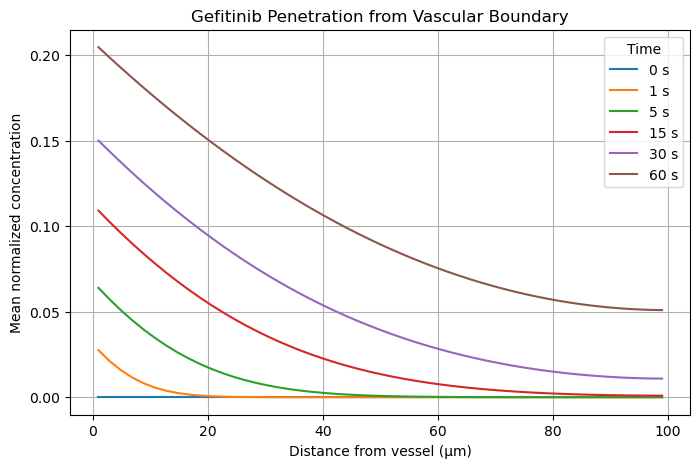

In [8]:
plt.figure(figsize=(8, 5))

for t in save_times:

    mean_profile = np.mean(saved_C[t], axis=1)

    plt.plot(
        x * 1e4,
        mean_profile,
        label=f"{t} s"
    )

plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Mean normalized concentration")
plt.title("Gefitinib Penetration from Vascular Boundary")
plt.legend(title="Time")
plt.grid(True)

plt.show()

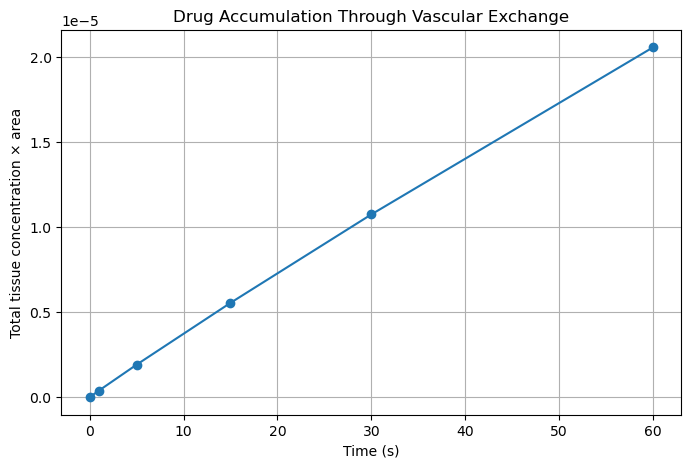

In [9]:
mass_values = []
mean_values = []
std_values = []

for t in save_times:

    field = saved_C[t]

    mass_values.append(np.sum(field) * dx * dy)
    mean_values.append(np.mean(field))
    std_values.append(np.std(field))


plt.figure(figsize=(8, 5))

plt.plot(save_times, mass_values, marker="o")

plt.xlabel("Time (s)")
plt.ylabel("Total tissue concentration × area")
plt.title("Drug Accumulation Through Vascular Exchange")
plt.grid(True)

plt.show()

In [10]:
# Reset initial condition
C = np.zeros((Nx, Ny))

saved_C = {0: C.copy()}

mass_values = {0: np.sum(C) * dx * dy}
cumulative_influx = {0: 0.0}

P_eff = 1 / (1 / Pv + dx / (2 * D))

total_influx = 0.0

for step in range(1, Nt + 1):

    # Vascular influx at the beginning of this timestep
    J_in = P_eff * (Cv - C[0, :])

    # Total flux entering across the vessel boundary
    influx_rate = np.sum(J_in) * dy

    # Accumulate entering drug
    total_influx += influx_rate * dt

    # Advance diffusion
    C = diffusion_step_vascular(
        C, D, Pv, Cv, dx, dy, dt
    )

    t = step * dt

    if step in [int(target / dt) for target in save_times]:

        t_saved = int(round(t))

        saved_C[t_saved] = C.copy()

        mass_values[t_saved] = np.sum(C) * dx * dy

        cumulative_influx[t_saved] = total_influx

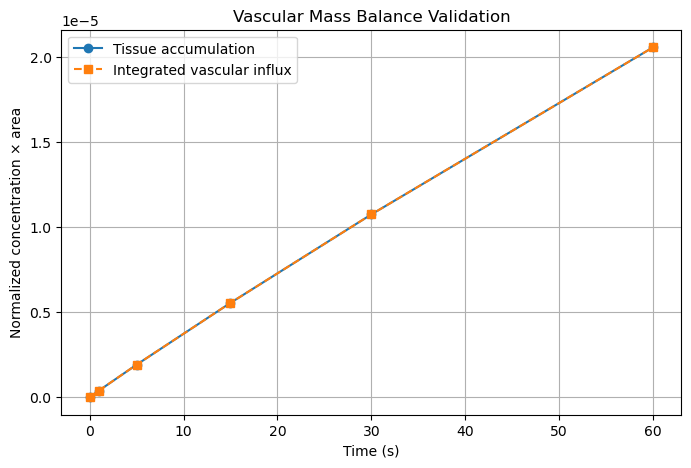

In [11]:
times = save_times

tissue_mass = np.array([mass_values[t] for t in times])

vascular_mass = np.array([
    cumulative_influx[t] for t in times
])

plt.figure(figsize=(8, 5))

plt.plot(times, tissue_mass, marker="o",
         label="Tissue accumulation")

plt.plot(times, vascular_mass, marker="s",
         linestyle="--",
         label="Integrated vascular influx")

plt.xlabel("Time (s)")
plt.ylabel("Normalized concentration × area")
plt.title("Vascular Mass Balance Validation")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
for t in times[1:]:

    tissue = mass_values[t]
    influx = cumulative_influx[t]

    error = abs(tissue - influx) / max(abs(influx), 1e-15)

    print(
        f"t = {t:>3} s | "
        f"Tissue = {tissue:.8e} | "
        f"Influx = {influx:.8e} | "
        f"Relative error = {error:.3e}"
    )

t =   1 s | Tissue = 3.91560358e-07 | Influx = 3.91560358e-07 | Relative error = 4.056e-16
t =   5 s | Tissue = 1.90851793e-06 | Influx = 1.90851793e-06 | Relative error = 2.219e-16
t =  15 s | Tissue = 5.53904103e-06 | Influx = 5.53904103e-06 | Relative error = 1.529e-16
t =  30 s | Tissue = 1.07327661e-05 | Influx = 1.07327661e-05 | Relative error = 2.683e-15
t =  60 s | Tissue = 2.05460113e-05 | Influx = 2.05460113e-05 | Relative error = 1.154e-15


## II. Vascular Exchange Sensitivity

Now that we have validated the primary outputs for one value of $P_v$, we will run the same model for multiple values of $P_v$, and see if it proves to be an essential parameter to the vascular diffusitivity of gefitinib.

In [13]:
# ==============================================
# Experiment 01A-2: Vascular exchange sensitivity
# ==============================================

Pv_values = [
    1e-6,
    3e-6,
    1e-5,
    3e-5,
    1e-4
]

D = 5e-7
Cv = 1.0

dt = 0.01
T = 60
Nt = int(T / dt)

# Results storage
results = {}

for Pv_test in Pv_values:

    # Reset tissue to drug-free condition
    C_test = np.zeros((Nx, Ny))

    # Run simulation
    for step in range(Nt):

        C_test = diffusion_step_vascular(
            C_test,
            D,
            Pv_test,
            Cv,
            dx,
            dy,
            dt
        )

    # ------------------------------------------
    # Extract measurements at final time
    # ------------------------------------------

    mean_concentration = np.mean(C_test)

    total_mass = np.sum(C_test) * dx * dy

    std_concentration = np.std(C_test)

    CV = (
        std_concentration / mean_concentration
        if mean_concentration != 0
        else np.nan
    )

    # Distal 10% of tissue
    distal_start = int(0.9 * Nx)

    distal_concentration = np.mean(
        C_test[distal_start:, :]
    )

    # Vessel-adjacent concentration
    vascular_concentration = np.mean(C_test[0, :])

    # Save outputs
    results[Pv_test] = {
        "field": C_test.copy(),
        "mean": mean_concentration,
        "mass": total_mass,
        "std": std_concentration,
        "CV": CV,
        "distal": distal_concentration,
        "vascular": vascular_concentration
    }

    print(f"Completed Pv = {Pv_test:.1e}")

print("\nAll simulations complete.")

Completed Pv = 1.0e-06
Completed Pv = 3.0e-06
Completed Pv = 1.0e-05
Completed Pv = 3.0e-05
Completed Pv = 1.0e-04

All simulations complete.


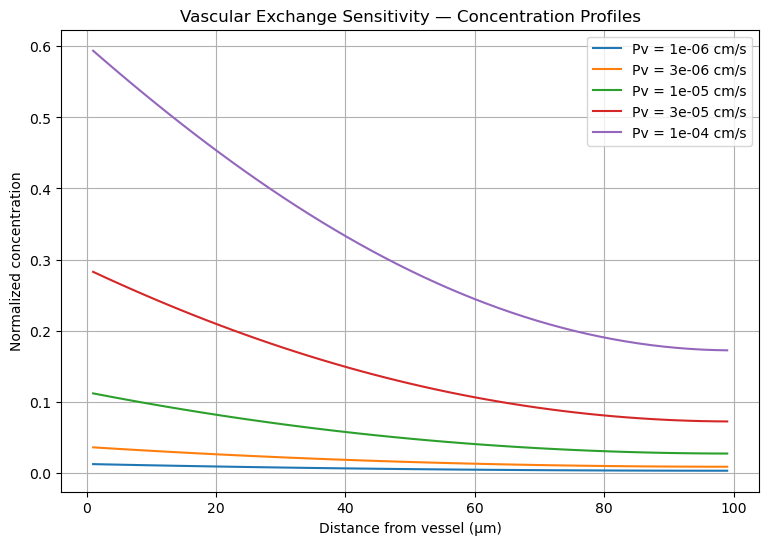

In [14]:
plt.figure(figsize=(9, 6))

for Pv_test in Pv_values:

    profile = np.mean(
        results[Pv_test]["field"],
        axis=1
    )

    plt.plot(
        x * 1e4,
        profile,
        label=f"Pv = {Pv_test:.0e} cm/s"
    )

plt.xlabel("Distance from vessel (μm)")
plt.ylabel("Normalized concentration")
plt.title("Vascular Exchange Sensitivity — Concentration Profiles")
plt.legend()
plt.grid(True)

plt.show()

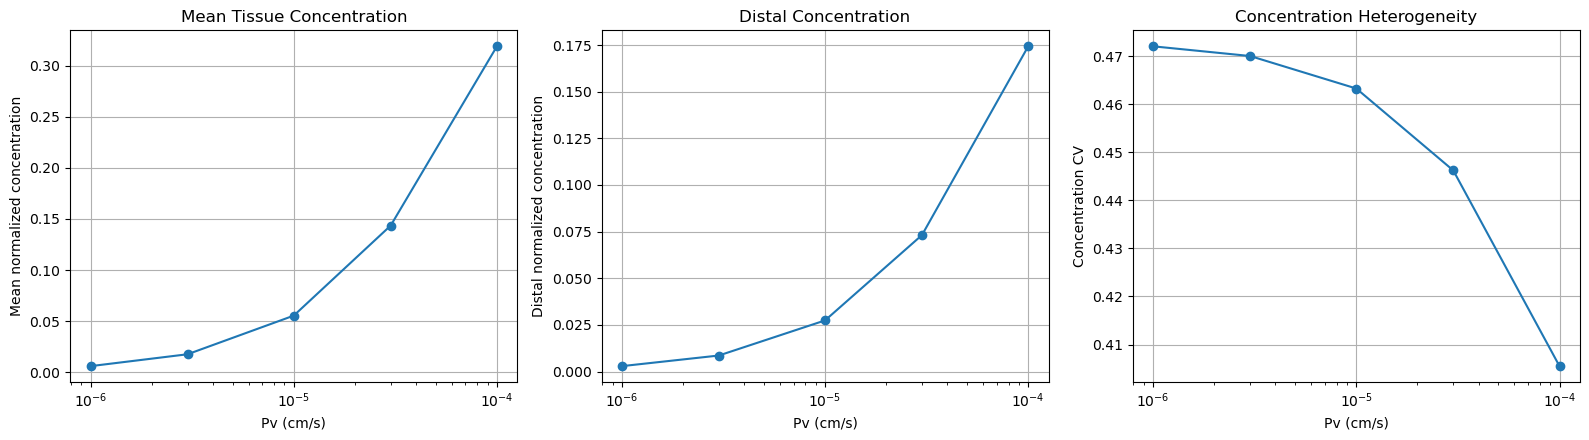

In [15]:
# Extract data
Pv_plot = np.array(Pv_values)

mean_values = np.array([
    results[p]["mean"] for p in Pv_values
])

distal_values = np.array([
    results[p]["distal"] for p in Pv_values
])

mass_values = np.array([
    results[p]["mass"] for p in Pv_values
])

CV_values = np.array([
    results[p]["CV"] for p in Pv_values
])


# Plot mean tissue concentration
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].semilogx(Pv_plot, mean_values, marker="o")
axes[0].set_title("Mean Tissue Concentration")
axes[0].set_xlabel("Pv (cm/s)")
axes[0].set_ylabel("Mean normalized concentration")
axes[0].grid(True)

# Distal concentration
axes[1].semilogx(Pv_plot, distal_values, marker="o")
axes[1].set_title("Distal Concentration")
axes[1].set_xlabel("Pv (cm/s)")
axes[1].set_ylabel("Distal normalized concentration")
axes[1].grid(True)

# Spatial heterogeneity
axes[2].semilogx(Pv_plot, CV_values, marker="o")
axes[2].set_title("Concentration Heterogeneity")
axes[2].set_xlabel("Pv (cm/s)")
axes[2].set_ylabel("Concentration CV")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [16]:
print(
    f"{'Pv (cm/s)' :>12} | "
    f"{'Mean C':>12} | "
    f"{'Distal C':>12} | "
    f"{'Mass':>12} | "
    f"{'CV':>10}"
)

print("-" * 70)

for p in Pv_values:
    r = results[p]

    print(
        f"{p:12.1e} | "
        f"{r['mean']:12.6f} | "
        f"{r['distal']:12.6f} | "
        f"{r['mass']:12.4e} | "
        f"{r['CV']:10.4f}"
    )

   Pv (cm/s) |       Mean C |     Distal C |         Mass |         CV
----------------------------------------------------------------------
     1.0e-06 |     0.005951 |     0.002899 |   1.1902e-06 |     0.4720
     3.0e-06 |     0.017564 |     0.008587 |   3.5127e-06 |     0.4700
     1.0e-05 |     0.055384 |     0.027400 |   1.1077e-05 |     0.4633
     3.0e-05 |     0.143526 |     0.073140 |   2.8705e-05 |     0.4462
     1.0e-04 |     0.318976 |     0.174294 |   6.3795e-05 |     0.4055


In [17]:
# Explicit diffusion stability check

dt_max = 1 / (
    2 * D * (1 / dx**2 + 1 / dy**2)
)

print(f"dx = {dx:.6e} cm")
print(f"dy = {dy:.6e} cm")
print(f"Current dt = {dt:.6e} s")
print(f"Approximate maximum dt = {dt_max:.6e} s")
print(f"dt / dt_max = {dt / dt_max:.4f}")

if dt <= dt_max:
    print("PASS: timestep satisfies the basic diffusion stability criterion.")
else:
    print("WARNING: timestep exceeds the basic diffusion stability criterion.")

dx = 1.960784e-04 cm
dy = 3.921569e-04 cm
Current dt = 1.000000e-02 s
Approximate maximum dt = 3.075740e-02 s
dt / dt_max = 0.3251
PASS: timestep satisfies the basic diffusion stability criterion.


## III. Spatial Grid Convergence Analysis

### Objective
Determine whether the numerical predictions of the vascular drug exchange model depend significantly on spatial grid resolution.

### Research question
Does increasing spatial resolution materially change the predicted drug concentration, accumulation, and penetration within the tissue domain?

### Hypothesis
As spatial resolution increases, the numerical solution should approach a stable result. If the measured outputs change substantially with grid refinement, the original resolution may be insufficient to accurately represent the concentration field.

### Experimental design
The physical domain, diffusivity, vascular exchange coefficient, vascular concentration, initial condition, and boundary conditions will remain constant. Only spatial grid resolution will be varied.

Three grid resolutions will be examined:
- Original resolution
- Approximately twice the original spatial resolution
- Approximately four times the original spatial resolution

Representative vascular exchange coefficients will be tested to examine whether grid sensitivity depends on the strength of vascular exchange.

### Measured outputs
- Mean tissue concentration
- Distal tissue concentration
- Total tissue drug accumulation
- Concentration coefficient of variation
- Concentration profile across the tissue

### Validation criterion
Numerical reliability will be evaluated by comparing outputs across grid resolutions. Decreasing differences between successive refinements would support convergence of the numerical solution.

### Scope
This experiment evaluates numerical resolution, not biological validity of the selected transport parameters.

In [18]:
# ============================================================
# Experiment 01A-3: Spatial Grid Convergence Analysis
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Fixed physical parameters
# ------------------------------------------------------------

D_test = D
Cv_test = Cv
T_test = 60.0

# Representative vascular exchange conditions
Pv_test_values = [1e-6, 1e-5, 1e-4]

# Preserve the original physical domain and original grid
Nx_original = Nx
Ny_original = Ny

# Refine spatial resolution while preserving domain dimensions
grid_levels = {
    "Original": (Nx_original, Ny_original),
    "2x finer": (
        2 * (Nx_original - 1) + 1,
        2 * (Ny_original - 1) + 1
    ),
    "4x finer": (
        4 * (Nx_original - 1) + 1,
        4 * (Ny_original - 1) + 1
    )
}

print("Grid convergence study initialized.")
print(grid_levels)

Grid convergence study initialized.
{'Original': (51, 51), '2x finer': (101, 101), '4x finer': (201, 201)}


In [19]:
# ============================================================
# 2. Grid convergence simulations
# ============================================================

convergence_results = {}

for grid_name, (Nx_g, Ny_g) in grid_levels.items():

    # Grid for this resolution
    x_g = np.linspace(0, Lx, Nx_g)
    y_g = np.linspace(0, Ly, Ny_g)

    dx_g = x_g[1] - x_g[0]
    dy_g = y_g[1] - y_g[0]

    # Explicit diffusion stability limit
    dt_diff_max = 1 / (
        2 * D_test * (
            1 / dx_g**2 + 1 / dy_g**2
        )
    )

    # Use a conservative safety factor
    dt_g = min(0.01, 0.8 * dt_diff_max)

    Nt_g = int(np.ceil(T_test / dt_g))
    dt_g = T_test / Nt_g  # Adjust to land exactly at T_test

    convergence_results[grid_name] = {}

    print(
        f"\n{grid_name}: "
        f"Nx={Nx_g}, Ny={Ny_g}, "
        f"dx={dx_g:.3e} cm, dy={dy_g:.3e} cm, "
        f"dt={dt_g:.3e} s"
    )

    # --------------------------------------------------------
    # Run each Pv
    # --------------------------------------------------------

    for Pv_g in Pv_test_values:

        C_g = np.zeros((Nx_g, Ny_g))

        for step in range(Nt_g):

            C_g = diffusion_step_vascular(
                C_g,
                D_test,
                Pv_g,
                Cv_test,
                dx_g,
                dy_g,
                dt_g
            )

        # ----------------------------------------------------
        # Calculate outputs
        # ----------------------------------------------------

        mean_C = np.mean(C_g)

        # Mass using physical domain area and mean concentration.
        # This avoids treating endpoint nodes as full cells.
        total_mass = mean_C * Lx * Ly

        std_C = np.std(C_g)

        CV_C = std_C / mean_C if mean_C > 0 else np.nan

        # Distal 10% of the domain
        distal_start = int(0.9 * Nx_g)

        distal_C = np.mean(C_g[distal_start:, :])

        # Average profile along y
        profile = np.mean(C_g, axis=1)

        convergence_results[grid_name][Pv_g] = {
            "field": C_g.copy(),
            "mean": mean_C,
            "mass": total_mass,
            "std": std_C,
            "CV": CV_C,
            "distal": distal_C,
            "profile": profile,
            "x": x_g.copy(),
            "dt": dt_g
        }

print("\nGrid convergence simulations complete.")


Original: Nx=51, Ny=51, dx=2.000e-04 cm, dy=4.000e-04 cm, dt=1.000e-02 s

2x finer: Nx=101, Ny=101, dx=1.000e-04 cm, dy=2.000e-04 cm, dt=6.400e-03 s

4x finer: Nx=201, Ny=201, dx=5.000e-05 cm, dy=1.000e-04 cm, dt=1.600e-03 s

Grid convergence simulations complete.


In [20]:
# ============================================================
# 3. Numerical comparison across resolutions
# ============================================================

print("\nGRID CONVERGENCE RESULTS")
print("=" * 100)

for Pv_g in Pv_test_values:

    print(f"\nPv = {Pv_g:.1e} cm/s")
    print("-" * 90)

    print(
        f"{'Grid':<12} "
        f"{'Mean C':>12} "
        f"{'Distal C':>12} "
        f"{'Mass':>14} "
        f"{'CV':>10}"
    )

    for grid_name in grid_levels:

        r = convergence_results[grid_name][Pv_g]

        print(
            f"{grid_name:<12} "
            f"{r['mean']:12.6e} "
            f"{r['distal']:12.6e} "
            f"{r['mass']:14.6e} "
            f"{r['CV']:10.5f}"
        )


# ------------------------------------------------------------
# Relative change from one resolution to the next
# ------------------------------------------------------------

print("\nRELATIVE CHANGE BETWEEN GRID RESOLUTIONS")
print("=" * 100)

for Pv_g in Pv_test_values:

    print(f"\nPv = {Pv_g:.1e} cm/s")

    for metric in ["mean", "distal", "mass", "CV"]:

        coarse = convergence_results["Original"][Pv_g][metric]
        medium = convergence_results["2x finer"][Pv_g][metric]
        fine = convergence_results["4x finer"][Pv_g][metric]

        change_1 = abs(medium - coarse) / max(abs(medium), 1e-15)
        change_2 = abs(fine - medium) / max(abs(fine), 1e-15)

        print(
            f"{metric:<8} | "
            f"Original → 2x: {change_1:.4%} | "
            f"2x → 4x: {change_2:.4%}"
        )


GRID CONVERGENCE RESULTS

Pv = 1.0e-06 cm/s
------------------------------------------------------------------------------------------
Grid               Mean C     Distal C           Mass         CV
Original     5.834146e-03 2.746523e-03   1.166829e-06    0.48814
2x finer     5.891910e-03 2.816009e-03   1.178382e-06    0.48019
4x finer     5.921220e-03 2.851632e-03   1.184244e-06    0.47618

Pv = 1.0e-05 cm/s
------------------------------------------------------------------------------------------
Grid               Mean C     Distal C           Mass         CV
Original     5.429942e-02 2.596797e-02   1.085988e-05    0.47930
2x finer     5.483702e-02 2.662112e-02   1.096740e-05    0.47137
4x finer     5.510953e-02 2.695566e-02   1.102191e-05    0.46738

Pv = 1.0e-04 cm/s
------------------------------------------------------------------------------------------
Grid               Mean C     Distal C           Mass         CV
Original     3.127970e-01 1.656446e-01   6.255940e-05    0.

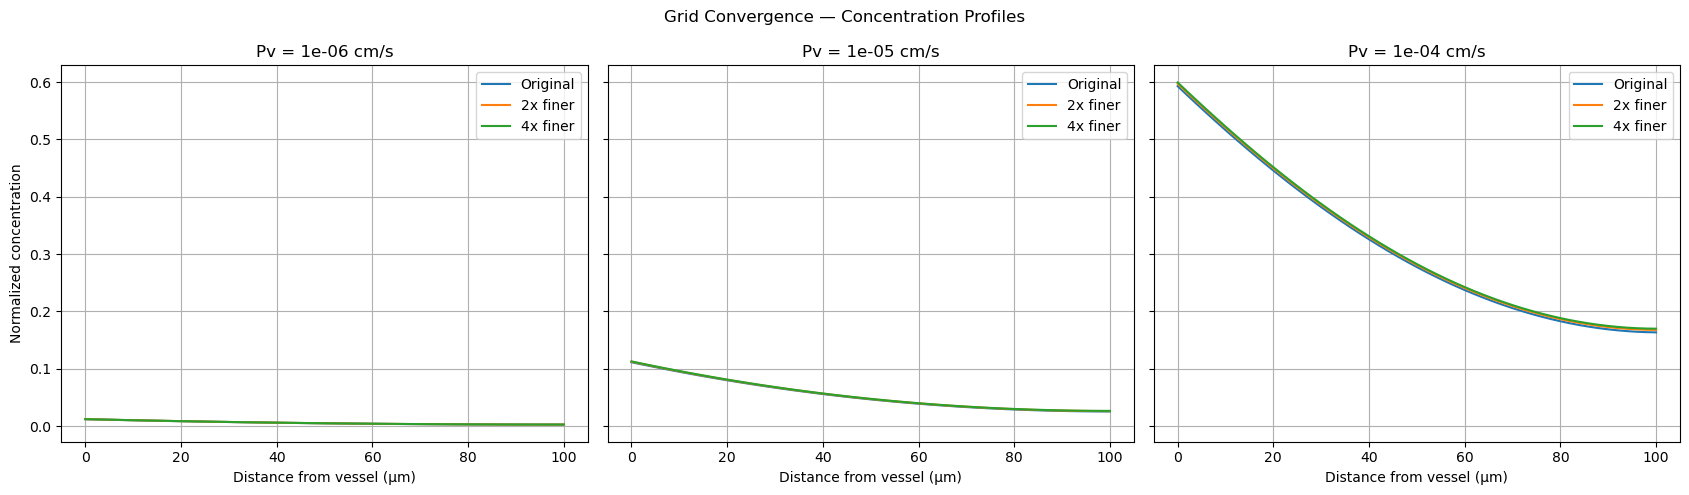

In [21]:
# ============================================================
# 4. Concentration profile convergence
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, Pv_g in zip(axes, Pv_test_values):

    for grid_name in grid_levels:

        r = convergence_results[grid_name][Pv_g]

        # Interpolate onto the original coordinate grid
        profile_interp = np.interp(
            x_original if 'x_original' in globals()
            else np.linspace(0, Lx, Nx_original),
            r["x"],
            r["profile"]
        )

        ax.plot(
            np.linspace(0, Lx, Nx_original) * 1e4,
            profile_interp,
            label=grid_name
        )

    ax.set_title(f"Pv = {Pv_g:.0e} cm/s")
    ax.set_xlabel("Distance from vessel (μm)")
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel("Normalized concentration")

fig.suptitle("Grid Convergence — Concentration Profiles")
plt.tight_layout()
plt.show()